## <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/prof/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


## <center>Curs 11 - Regresori ML: exemple cod</center>


**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. univ. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prof/SEED/blob/main/cursuri/04-regresie/extra-04-regresori-ml.ipynb)

In [ ]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/prof/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/04-regresie
sys.path.insert(0, os.path.abspath("../.."))

Pentru evaluarea regresorilor scikitlearn propune metricile de la sectiunea Regression de aici:

https://scikit-learn.org/stable/modules/model_evaluation.html



Daca adevaratul model este un model liniar, atunci media reziduurilor ar fi zero.

Daca media reziduurilor este departe de 0, atunci modelul liniar nu e cel dorit.

Când regresori liniari și neliniari sunt evaluati, putem considera scorul **explained_variance** ca fiind o generalizare a lui **$R^2$**.

Metrici uzuale folosite pentru antrenare în scopul prognozării sunt **MAE** și **MAPE** discutate și la cursul cu regresia liniară.

In [49]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import mean_absolute_percentage_error as mape
from sklearn.model_selection import GridSearchCV
from sklearn import metrics

## Setul de date

<a href="https://www.kaggle.com/code/prasadperera/the-boston-housing-dataset">The Boston Housing Dataset</a>

The Boston Housing Dataset is a derived from information collected by the U.S. Census Service concerning housing in the area of Boston MA. The following describes the dataset columns:

- CRIM - per capita crime rate by town
- ZN - proportion of residential land zoned for lots over 25,000 sq.ft.
- INDUS - proportion of non-retail business acres per town.
- CHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)
- NOX - nitric oxides concentration (parts per 10 million)
- RM - average number of rooms per dwelling
- AGE - proportion of owner-occupied units built prior to 1940
- DIS - weighted distances to five Boston employment centres
- RAD - index of accessibility to radial highways
- TAX - full-value property-tax rate per USD10,000
- PTRATIO - pupil-teacher ratio by town
- B - 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
- LSTAT - % lower status of the population
- MEDV - Median value of owner-occupied homes in USD1000's

In [50]:
bostonhousing = pd.read_csv('./date/boston_housing.csv')
bostonhousing = bostonhousing.dropna(how='any')
bostonhousing.info()

target_col = 'MEDV'

<class 'pandas.core.frame.DataFrame'>
Index: 401 entries, 0 to 449
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     401 non-null    float64
 1   ZN       401 non-null    float64
 2   INDUS    401 non-null    float64
 3   CHAS     401 non-null    float64
 4   NOX      401 non-null    float64
 5   RM       401 non-null    float64
 6   age      401 non-null    float64
 7   DIS      401 non-null    float64
 8   RAD      401 non-null    int64  
 9   IMPOZIT  401 non-null    float64
 10  PTRATIO  401 non-null    float64
 11  B        401 non-null    float64
 12  LSTAT%   401 non-null    float64
 13  MEDV     401 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 47.0 KB


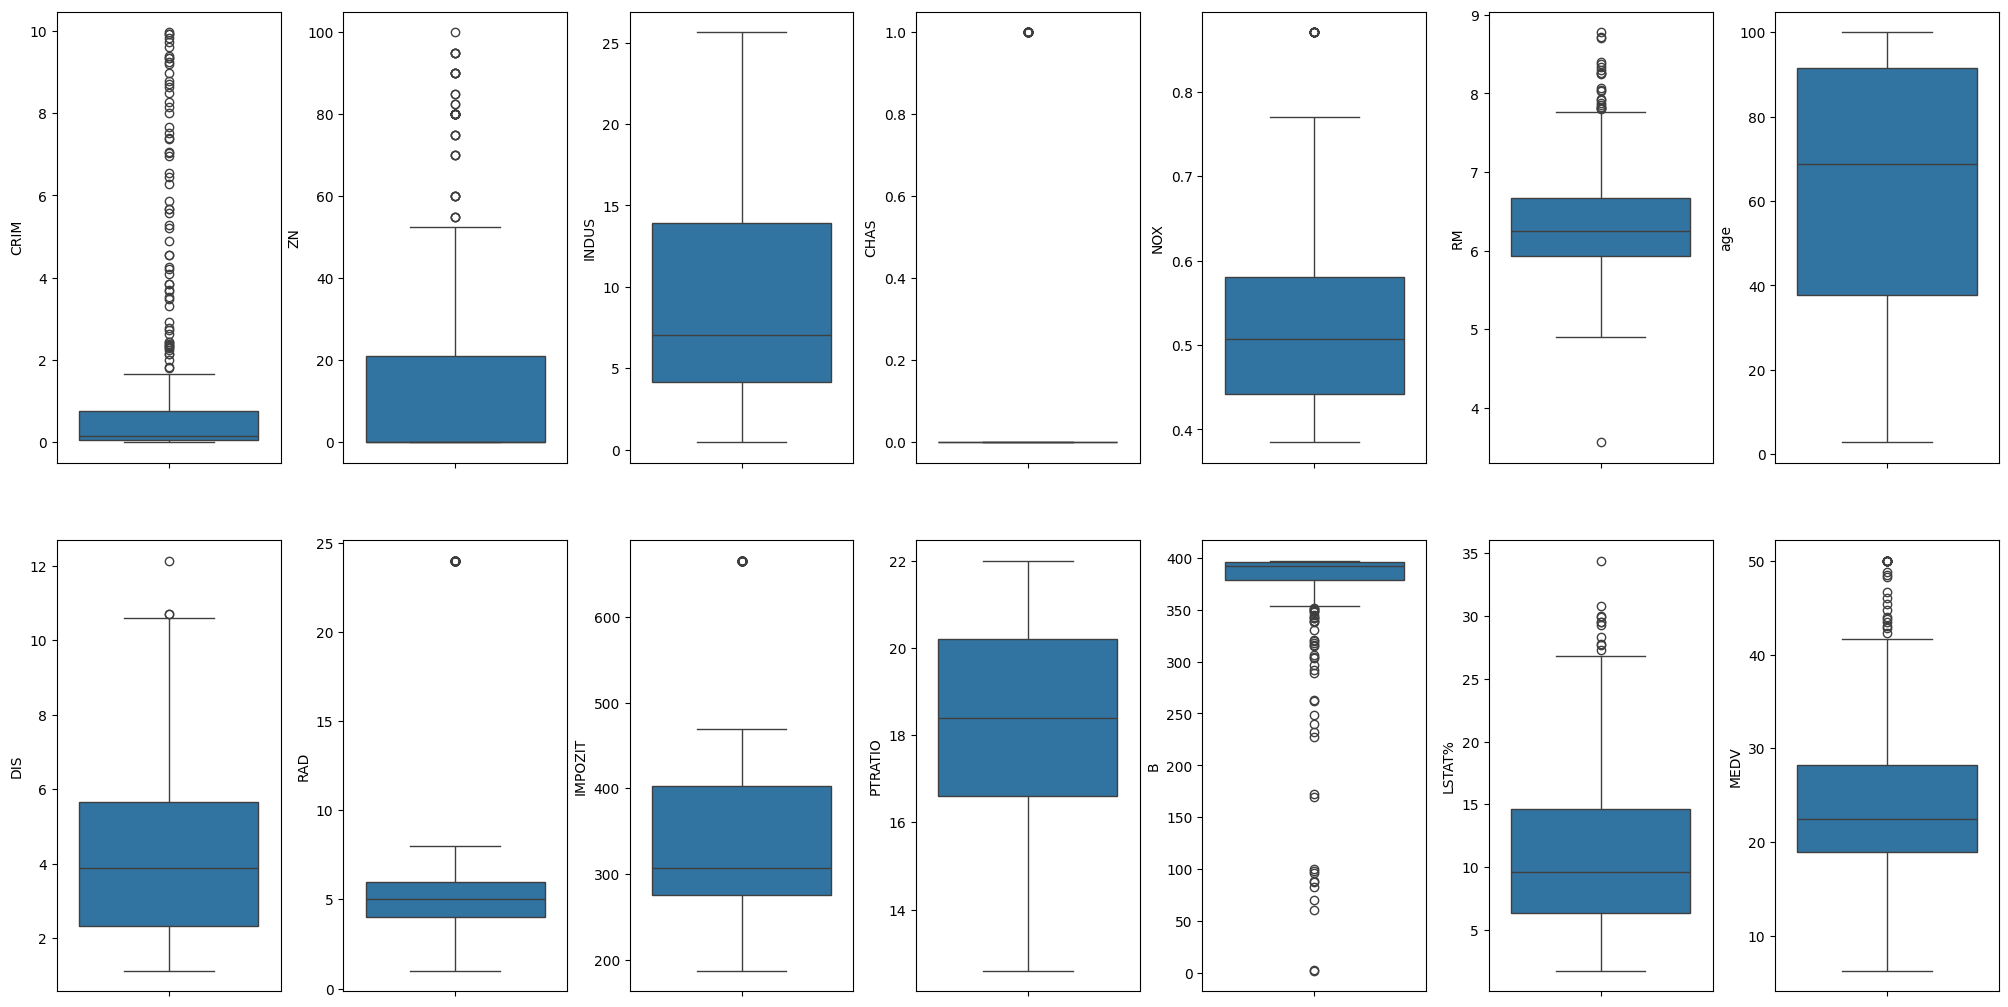

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

fig, axs = plt.subplots(ncols=7, nrows=2, figsize=(20, 10))
index = 0
axs = axs.flatten()
for k,v in bostonhousing.items():
    sns.boxplot(y=k, data=bostonhousing, ax=axs[index])
    index += 1
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)

<Axes: >

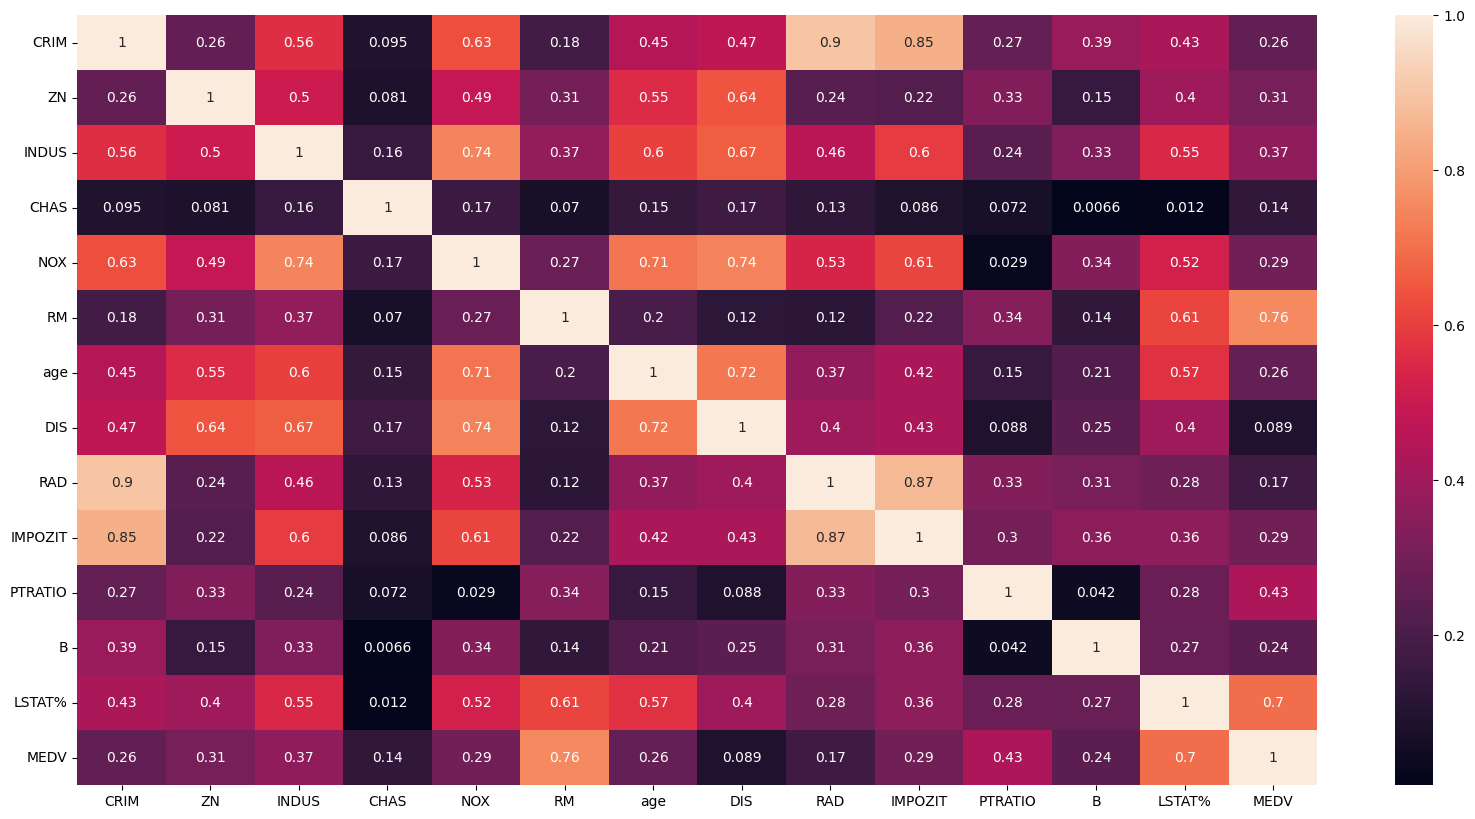

In [52]:
plt.figure(figsize=(20, 10))
sns.heatmap(bostonhousing.corr().abs(),  annot=True)

Din matricea de corelație, vedem că IMPOZIT și RAD sunt caracteristici foarte corelate. Coloanele LSTAT, INDUS, RM, IMPOZIT, NOX, PTRAIO au un scor de corelare peste 0,5 cu MEDV, ceea ce este un bun indiciu ca să îi utilizăm ca predictori. Să punem aceste coloane în raport cu MEDV.

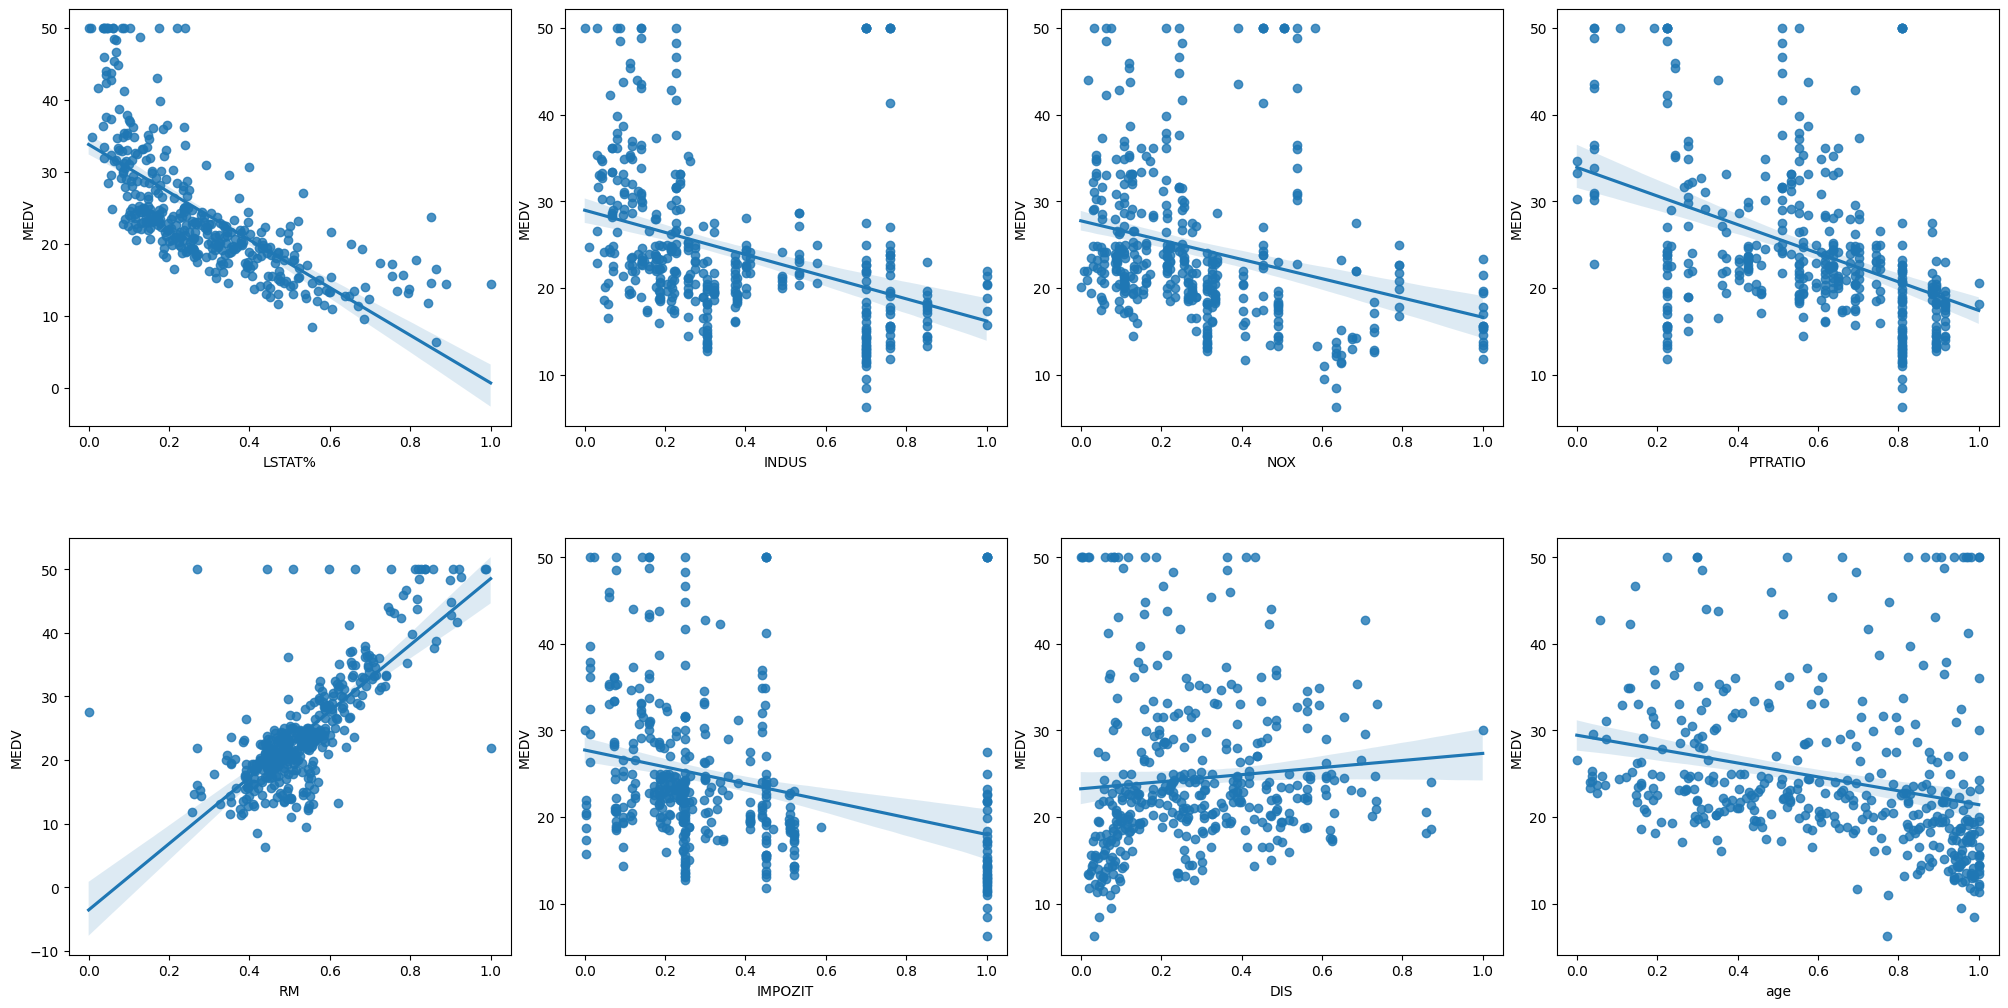

In [53]:
from sklearn import preprocessing
# Let's scale the columns before plotting them against MEDV
min_max_scaler = preprocessing.MinMaxScaler()
column_sels = ['LSTAT%', 'INDUS', 'NOX', 'PTRATIO', 'RM', 'IMPOZIT', 'DIS', 'age']
x = bostonhousing.loc[:,column_sels]
y = bostonhousing['MEDV']
x = pd.DataFrame(data=min_max_scaler.fit_transform(x), columns=column_sels)
fig, axs = plt.subplots(ncols=4, nrows=2, figsize=(20, 10))
index = 0
axs = axs.flatten()
for i, k in enumerate(column_sels):
    sns.regplot(y=y, x=x[k], ax=axs[i])
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)

## Exemplu de antrenare regresor kNN cu GridSearch

In [54]:
from sklearn.neighbors import KNeighborsRegressor

In [55]:
def antrenament_scikitlearn_knnr(X,y):
    
    # instațiem un model
    knnr = KNeighborsRegressor()#random_state=42)
    
    # setăm parametrii pe care vrem să îi încercăm
    param_grid = {
                    'n_neighbors': list(range(2,20))
                 }
    
    # folosim  antrenare cu validare încrucișată
    CV_knnr = GridSearchCV(estimator=knnr, 
                          param_grid=param_grid, 
                          scoring = 'neg_mean_absolute_error', # aici e diferenta fata de clasificator - metrica aleasa pentru evaluare
                          cv = 10, 
                          n_jobs = 6,
                         error_score='raise')
    # pasut de antrenare
    CV_knnr.fit(X, y)
    
    # returnăm cei mai buni parametrii și cel mai bun model
    return CV_knnr.best_params_, CV_knnr.best_estimator_,CV_knnr.cv_results_

Iteration 0


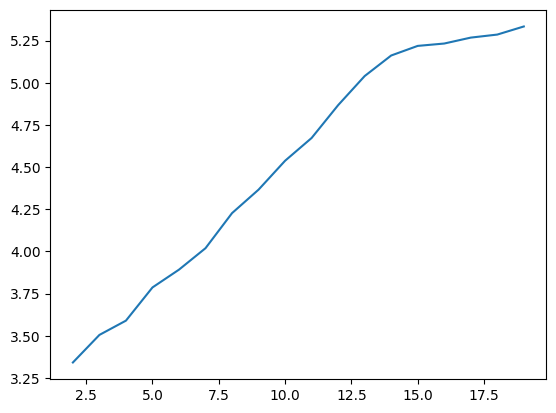

Iteration 1


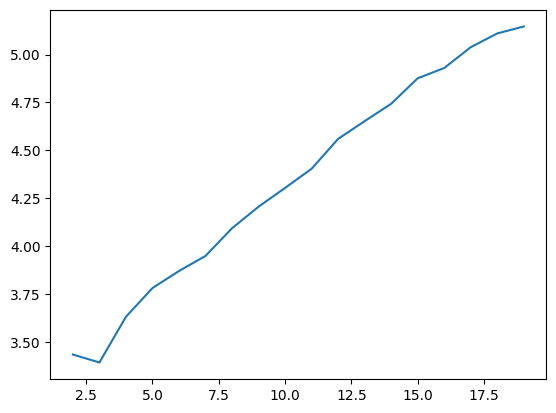

Iteration 2


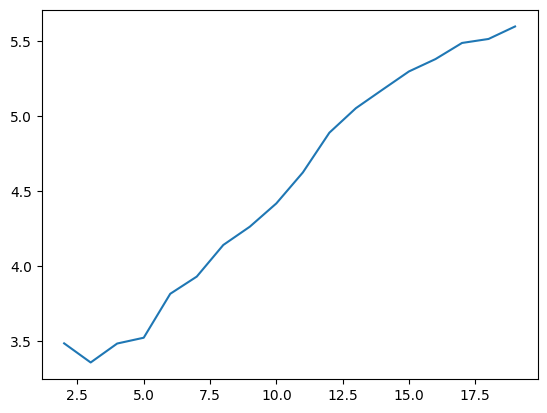

Iteration 3


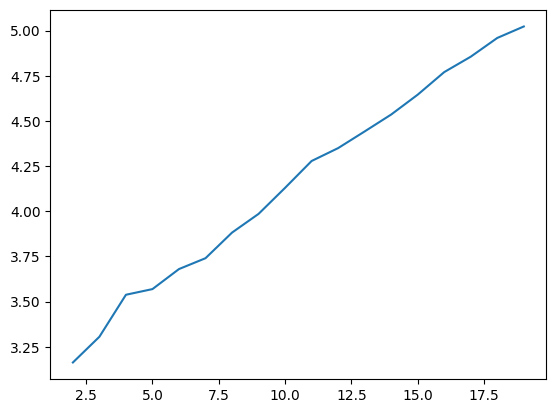

Iteration 4


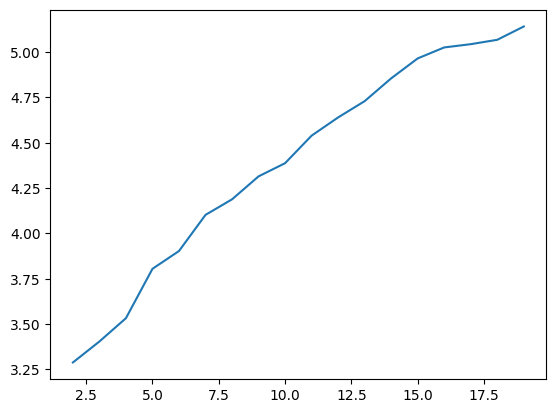

In [56]:
# 5 iteratii 
results_CV_paralel = []
for i in range(5):
    
    print("Iteration {0}".format(i))
    # Split dataset în set de antrenament și set de test 
    X_train, X_test, y_train, y_test = train_test_split(bostonhousing, 
                                                        bostonhousing[target_col], 
                                                        test_size=0.3) # 70% training / 30% test
    
    #params,model = antrenament_scikitlearn_rfc(X_train.to_numpy(), y_train.to_numpy())
    params,model,full_cv_results = antrenament_scikitlearn_knnr(X_train, y_train)
    
    df = pd.DataFrame()
    df['n_neighbors'] = [p['n_neighbors']  for p in full_cv_results['params']]
    df['mean_test_score'] = abs(full_cv_results['mean_test_score'])

    # Extract the date and close price columns
    vecini = df['n_neighbors']
    mean_test_score = df['mean_test_score']

    # Create a line plot
    plt.plot(vecini, mean_test_score)

    # Show the plot
    plt.show()
    
    # prognozăm cu cel mai bun model
    y_test_pred = model.predict(X_test)
    results_CV_paralel.append({
        'mae': mae(y_true = y_test, y_pred=y_test_pred),
        'mape': f"{100*mape(y_true = y_test, y_pred=y_test_pred):.3f}%",
        'parametrii': params}
        )

In [57]:
print("Average MAE knnr:", sum([r['mae'] for r in results_CV_paralel])/len(results_CV_paralel))

pd.DataFrame(results_CV_paralel)

Average MAE knnr: 3.259035812672176


,mae,mape,parametrii
0,3.185537,13.674%,{'n_neighbors': 2}
1,3.106061,12.023%,{'n_neighbors': 3}
2,3.296970,13.707%,{'n_neighbors': 3}
3,3.532231,13.518%,{'n_neighbors': 2}
4,3.174380,14.720%,{'n_neighbors': 2}


## Exemplu de antrenare arbore de regresie cu GridSearch

In [58]:
from sklearn.tree import DecisionTreeRegressor

In [59]:
def antrenament_scikitlearn_dtr(X,y):
    
    # instațiem un model
    dtr = DecisionTreeRegressor()#random_state=42)
    
    # setăm parametrii pe care vrem să îi încercăm
    # Hyper parameters range intialization for tuning 

    param_grid={
                "splitter":["best","random"],
                "max_depth" : [3,5,7],
               "min_samples_leaf":[3,4,5,6,7],
               "min_weight_fraction_leaf":[0.1,0.2,0.3,0.4,0.5],
               "max_features":["log2","sqrt",None],
               "max_leaf_nodes":[None,10,50,90] 
               }
    
    # folosim  antrenare cu validare încrucișată
    CV_dtr = GridSearchCV(estimator=dtr, 
                          param_grid=param_grid, 
                          scoring = 'neg_mean_absolute_error', # aici e diferenta fata de clasificator - metrica aleasa pentru evaluare
                          cv = 10, 
                          n_jobs = 6,
                         error_score='raise')
    # pasut de antrenare
    CV_dtr.fit(X, y)
    
    # returnăm cei mai buni parametrii și cel mai bun model
    return CV_dtr.best_params_, CV_dtr.best_estimator_

In [60]:
# 5 iteratii 
results_CV_paralel = []
for i in range(5):
    
    print("Iteration {0}".format(i))
    # Split dataset în set de antrenament și set de test 
    X_train, X_test, y_train, y_test = train_test_split(bostonhousing, 
                                                        bostonhousing[target_col], 
                                                        test_size=0.3) # 70% training / 30% test
    
    #params,model = antrenament_scikitlearn_rfc(X_train.to_numpy(), y_train.to_numpy())
    params,model = antrenament_scikitlearn_dtr(X_train, y_train)
    
    # prognozăm cu cel mai bun model
    y_test_pred = model.predict(X_test)
    results_CV_paralel.append({
        'mae': mae(y_true = y_test, y_pred=y_test_pred),
        'mape': f"{100*mape(y_true = y_test, y_pred=y_test_pred):.3f}%",
        'parametrii': params}
        )

Iteration 0
Iteration 1
Iteration 2
Iteration 3
Iteration 4


In [61]:
print("Average MAE:", sum([r['mae'] for r in results_CV_paralel])/len(results_CV_paralel))
pd.options.display.max_colwidth = 200
pd.DataFrame(results_CV_paralel)

Average MAE: 1.4339214982998931


,mae,mape,parametrii
0,1.216797,5.581%,"{'max_depth': 7, 'max_features': None, 'max_leaf_nodes': 10, 'min_samples_leaf': 3, 'min_weight_fraction_leaf': 0.1, 'splitter': 'best'}"
1,2.426397,8.297%,"{'max_depth': 5, 'max_features': None, 'max_leaf_nodes': 90, 'min_samples_leaf': 3, 'min_weight_fraction_leaf': 0.1, 'splitter': 'best'}"
2,1.106382,4.950%,"{'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_samples_leaf': 5, 'min_weight_fraction_leaf': 0.1, 'splitter': 'best'}"
3,1.283905,5.696%,"{'max_depth': 5, 'max_features': None, 'max_leaf_nodes': 10, 'min_samples_leaf': 4, 'min_weight_fraction_leaf': 0.1, 'splitter': 'best'}"
4,1.136127,6.186%,"{'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_samples_leaf': 5, 'min_weight_fraction_leaf': 0.1, 'splitter': 'best'}"


## Exemplu de antrenare regresor Random Forest cu GridSearch

In [62]:
from sklearn.ensemble import RandomForestRegressor




In [63]:
bostonhousing

,CRIM,ZN,INDUS,CHAS,NOX,RM,age,DIS,RAD,IMPOZIT,PTRATIO,B,LSTAT%,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
443,9.96654,0.0,18.10,0.0,0.740,6.485,100.0,1.9784,24,666.0,20.2,386.73,18.85,15.4
446,6.28807,0.0,18.10,0.0,0.740,6.341,96.4,2.0720,24,666.0,20.2,318.01,17.79,14.9
447,9.92485,0.0,18.10,0.0,0.740,6.251,96.6,2.1980,24,666.0,20.2,388.52,16.44,12.6
448,9.32909,0.0,18.10,0.0,0.713,6.185,98.7,2.2616,24,666.0,20.2,396.90,18.13,14.1


In [64]:
def antrenament_scikitlearn_rfr(X,y):
    
    # instațiem un model
    rfr = RandomForestRegressor()#random_state=42)
    
    # setăm parametrii pe care vrem să îi încercăm
    param_grid = {
                    'n_estimators': [100,1000], #[100, 200, 500, 1000],
                    'max_features': ['sqrt','log2', int(round(X.shape[0]/3,0)) ], #cutuma pt regresie: 1/3 din numarul de atribute
                    'max_samples' : [0.1, 0.2, 0.3, 0.4] ,
                    #'criterion' :['gini', 'entropy']
                 }
    
    # folosim  antrenare cu validare încrucișată
    CV_rfr = GridSearchCV(estimator=rfr, 
                          param_grid=param_grid, 
                          scoring = 'neg_mean_absolute_error', # aici e diferenta fata de clasificator - metrica aleasa pentru evaluare
                          cv = 10, 
                          n_jobs = 6,
                         error_score='raise')
    # pasut de antrenare
    CV_rfr.fit(X, y)
    
    # returnăm cei mai buni parametrii și cel mai bun model
    return CV_rfr.best_params_, CV_rfr.best_estimator_



In [65]:
# 5 iteratii 
results_CV_paralel = []
for i in range(5):
    
    print("Iteration {0}".format(i))
    # Split dataset în set de antrenament și set de test 
    X_train, X_test, y_train, y_test = train_test_split(bostonhousing, 
                                                        bostonhousing[target_col], 
                                                        test_size=0.3) # 70% training / 30% test
    
    #params,model = antrenament_scikitlearn_rfc(X_train.to_numpy(), y_train.to_numpy())
    params,model = antrenament_scikitlearn_rfr(X_train, y_train)
    
    # prognozăm cu cel mai bun model
    y_test_pred = model.predict(X_test)
    results_CV_paralel.append({
        'mae': mae(y_true = y_test, y_pred=y_test_pred),
        'mape': f"{100*mape(y_true = y_test, y_pred=y_test_pred):.3f}%",
        'parametrii': params}
        )
    



Iteration 0
Iteration 1
Iteration 2
Iteration 3
Iteration 4


In [66]:
print("Average MAE:", sum([r['mae'] for r in results_CV_paralel])/len(results_CV_paralel))

pd.DataFrame(results_CV_paralel)

Average MAE: 0.196898677685942


,mae,mape,parametrii
0,0.120979,0.663%,"{'max_features': 93, 'max_samples': 0.4, 'n_estimators': 1000}"
1,0.156022,0.605%,"{'max_features': 93, 'max_samples': 0.4, 'n_estimators': 1000}"
2,0.201533,1.228%,"{'max_features': 93, 'max_samples': 0.4, 'n_estimators': 1000}"
3,0.156131,0.626%,"{'max_features': 93, 'max_samples': 0.4, 'n_estimators': 1000}"
4,0.349828,1.350%,"{'max_features': 93, 'max_samples': 0.4, 'n_estimators': 1000}"


# Exemplu de antrenare regresor XGBoost cu Grid Search pentru parametrii

### 1. implementarea din scikitlearn

In [67]:
from sklearn.ensemble import GradientBoostingRegressor
import time

In [68]:
def antrenament_scikitlearn_xgb_r(X,y):
    
    xgb = GradientBoostingRegressor()#random_state=42)
    param_grid = {
                    'n_estimators' : [10, 100, 1000],
                    'learning_rate' : [0.001, 0.01, 0.1],
                    #'subsample' : [0.5, 0.7, 1.0],
                    #'max_depth' : [3, 7, 9]
                 }
    CV_xgb = GridSearchCV(estimator=xgb, 
                          param_grid=param_grid,
                          scoring = 'explained_variance',
                          cv= 10, 
                          n_jobs = 6)
    CV_xgb.fit(X, y)
    
    return CV_xgb.best_params_, CV_xgb.best_estimator_



Apelarea functiei de antrenament:

In [69]:
# 100 de iteratii 

tic = time.time()
results_CV_paralel = []
for i in range(5):
    
    print("Iteration {0}".format(i))
    # Split dataset into training set and test set
    X_train, X_test, y_train, y_test = train_test_split(bostonhousing, bostonhousing[target_col], test_size=0.3) # 70% training and 30% test
    
    params,model = antrenament_scikitlearn_xgb_r(X_train, y_train)
    
    yhat = model.predict(X_test)
    error = abs(y_test-yhat.reshape(y_test.shape[0])).sum()/y_test.shape[0]
    res_dict = pd.Series(abs(y_test-yhat.reshape(y_test.shape[0]))).describe(
    percentiles = [0.75,.8,0.95,0.99]).to_dict()
    res_dict['mae'] = mae(y_true = y_test, y_pred=yhat)
    res_dict['mape'] = f"{100*mape(y_true = y_test, y_pred=yhat):.3f}%"
    res_dict['parametrii'] = params
    results_CV_paralel.append(res_dict)
    
toc = time.time()

print("Durata antrenament:", toc-tic)

Iteration 0
Iteration 1
Iteration 2
Iteration 3
Iteration 4
Durata antrenament: 15.178242683410645


In [70]:
print("Average MAE xgboost:", sum([r['mae'] for r in results_CV_paralel])/len(results_CV_paralel))

pd.DataFrame(results_CV_paralel)

Average MAE xgboost: 0.09879760620062629


,count,mean,std,min,50%,75%,80%,95%,99%,max,mae,mape,parametrii
0,121.0,0.074705,0.145493,0.000007,0.000577,0.100123,0.100380,0.299503,0.783569,0.804187,0.074705,0.341%,"{'learning_rate': 0.01, 'n_estimators': 1000}"
1,121.0,0.093595,0.131232,0.000664,0.067730,0.121255,0.129235,0.223688,0.739314,1.025003,0.093595,0.464%,"{'learning_rate': 0.1, 'n_estimators': 100}"
2,121.0,0.092866,0.246876,0.000002,0.000522,0.100171,0.100411,0.309042,1.020389,2.212257,0.092866,0.566%,"{'learning_rate': 0.01, 'n_estimators': 1000}"
3,121.0,0.083832,0.312961,0.000004,0.000388,0.099566,0.100189,0.201066,0.933053,3.209859,0.083832,0.722%,"{'learning_rate': 0.01, 'n_estimators': 1000}"
4,121.0,0.148991,0.265249,0.000259,0.058785,0.133002,0.154480,0.704364,1.385223,1.489978,0.148991,0.732%,"{'learning_rate': 0.1, 'n_estimators': 1000}"


### 2. implementarea din xgboost

In [ ]:
import xgboost as xgb
xgb.set_config(verbosity=0)


In [26]:
def antrenament_scikitlearn_xgboost_r(X,y):
    
    xgb_reg = xgb.XGBRegressor()#random_state=42)
    param_grid = {
                    'n_estimators' : [10, 100, 1000],
                    'eta' : [0.001, 0.01, 0.1],
                    'max_depth' : [3, 7, 9],
                    'subsample' : [0.5, 0.7, 1.0],
                    'colsample_bytree':[0.5, 0.7, 1.0],
                    'tree_method':['hist'] #typilcally fastest according to https://www.anyscale.com/blog/how-to-speed-up-xgboost-model-training
                    
                 }
    CV_xgb = GridSearchCV(estimator=xgb_reg, 
                          param_grid=param_grid,
                          scoring = 'explained_variance',
                          cv= 10, 
                          n_jobs = 6)
    CV_xgb.fit(X, y)
    
    return CV_xgb.best_params_, CV_xgb.best_estimator_

In [ ]:
# cateva de iteratii 

tic = time.time()
results_CV_paralel = []
for i in range(5):
    
    print("Iteration {0}".format(i))
    # Split dataset into training set and test set
    X_train, X_test, y_train, y_test = train_test_split(bostonhousing, bostonhousing[target_col], test_size=0.3) # 70% training and 30% test
    
    params,model = antrenament_scikitlearn_xgboost_r(X_train, y_train)
    
    yhat = model.predict(X_test)
    error = abs(y_test-yhat.reshape(y_test.shape[0])).sum()/y_test.shape[0]
    res_dict = pd.Series(abs(y_test-yhat.reshape(y_test.shape[0]))).describe(
    percentiles = [0.75,.8,0.95,0.99]).to_dict()
    res_dict['mae'] = mae(y_true = y_test, y_pred=yhat)
    res_dict['mape'] = f"{100*mape(y_true = y_test, y_pred=y_test_pred):.3f}%"
    res_dict['parametrii'] = params
    results_CV_paralel.append(res_dict)

toc = time.time()
print('Durata antrenament:', toc-tic)
print("Average MAE xgboost from xgboot:", sum([r['mae'] for r in results_CV_paralel])/len(results_CV_paralel))

pd.DataFrame(results_CV_paralel)

Iteration 0
Iteration 1
Iteration 2
Iteration 3
Iteration 4
Durata antrenament: 224.62109756469727
Average MAE xgboost from xgboot: 0.1552275561498216


,count,mean,std,min,50%,75%,80%,95%,99%,max,mae,mape,parametrii
0,121.0,0.175063,0.557888,0.000446,0.042637,0.132467,0.147815,0.530496,2.593581,5.049547,0.175063,0.417%,"{'colsample_bytree': 1.0, 'eta': 0.01, 'max_depth': 3, 'n_estimators': 1000, 'subsample': 0.5, 'tree_method': 'hist'}"
1,121.0,0.082444,0.157204,0.000073,0.021056,0.097367,0.110038,0.377721,0.601918,1.234709,0.082444,0.370%,"{'colsample_bytree': 1.0, 'eta': 0.01, 'max_depth': 9, 'n_estimators': 1000, 'subsample': 0.5, 'tree_method': 'hist'}"
2,121.0,0.167645,0.548769,0.000230,0.017337,0.114680,0.145105,0.551363,2.623804,4.989206,0.167645,0.411%,"{'colsample_bytree': 1.0, 'eta': 0.01, 'max_depth': 3, 'n_estimators': 1000, 'subsample': 0.5, 'tree_method': 'hist'}"
3,121.0,0.139596,0.252561,0.000085,0.030739,0.124535,0.175226,0.743952,1.092495,1.283767,0.139596,0.409%,"{'colsample_bytree': 1.0, 'eta': 0.01, 'max_depth': 3, 'n_estimators': 1000, 'subsample': 0.5, 'tree_method': 'hist'}"
4,121.0,0.211391,0.579989,0.000593,0.039415,0.113144,0.133208,1.146285,2.722803,4.686394,0.211391,0.433%,"{'colsample_bytree': 1.0, 'eta': 0.01, 'max_depth': 3, 'n_estimators': 1000, 'subsample': 0.5, 'tree_method': 'hist'}"
